# DS1 data preprocessing

Prepares DS1 (UCI Chronic Kidney Disease, CKD vs not CKD) for clustering and the models. Input is the feature-engineered data from `3_Feature_Engineering` (`feature_engineered_data/`), found through `configs/config.json`; it is split here into train and test before anything is learned. Output is `preprocessed_data/DS1_train.csv` and `preprocessed_data/DS1_test.csv`: no missing values, numbers scaled, text encoded as 0/1.

**Pipeline**

| Step | Features | Learned from | Needed by |
|---|---|---|---|
| Train/test split | stratified 80/20, seed from the config | fixed | all models |
| Impossible values to missing | sodium < 100, potassium > 10 | fixed clinical rule | all models |
| Fill missing | numeric: training median; text: training most frequent value | train only | all models (scikit-learn cannot take NaN) |
| log1p | right-skewed numeric features (skew > 1), not graded scales, scores or the already logged log_bu, log_sc | train only | kNN, Gaussian Naive Bayes, MLP, clustering |
| StandardScaler | all numeric features | train only | kNN, MLP, clustering (distance based) |
| 0/1 encoding | 10 binary text features, fixed category order | fixed | all models |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, FunctionTransformer

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]

names = {
    "age": "Age", "bp": "Blood pressure", "sg": "Specific gravity", "al": "Albumin", "su": "Sugar",
    "rbc": "Red blood cells", "pc": "Pus cells", "pcc": "Pus cell clumps", "ba": "Bacteria",
    "bgr": "Blood glucose", "bu": "Blood urea", "sc": "Serum creatinine", "sod": "Sodium", "pot": "Potassium",
    "hemo": "Hemoglobin", "pcv": "Packed cell volume", "wbcc": "White blood cell count", "rbcc": "Red blood cell count",
    "htn": "Hypertension", "dm": "Diabetes mellitus", "cad": "Coronary artery disease", "appet": "Appetite",
    "pe": "Pedal edema", "ane": "Anemia",
    "comorbidity_count": "Comorbidity count", "urea_creatinine_ratio": "Urea/creatinine ratio",
    "log_bu": "Log urea", "log_sc": "Log creatinine", "urine_abnormality_score": "Urine abnormality score",
    "bu_sc_interaction": "Urea x creatinine",
}

## 1. Load and split

In [2]:
df = pd.read_csv(base / ds["files"]["feature_engineered"][0], na_values=ds["na_values"] or None)
train_df, test_df = train_test_split(
    df,
    test_size=config["training"]["test_size"],
    random_state=config["training"]["random_state"],
    stratify=df[target],
)

X_train, y_train = train_df.drop(columns=[target]), train_df[target]
X_test, y_test = test_df.drop(columns=[target]), test_df[target]

num_cols = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
text_cols = [c for c in X_train.columns if c not in num_cols]
order = ["notckd", "ckd"]
short = ["Not CKD", "CKD"]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Numeric:", len(num_cols), "| Text:", len(text_cols))

Train: (320, 30) Test: (80, 30)
Numeric: 20 | Text: 10


**Observation:**
- The data is split first (stratified 80/20, test_size and random_state from the config), so CKD and not CKD keep the same proportions in train and test
- Every decision below uses the training set only; the test set is only transformed (Géron, 2022)

## 2. Explore the training set

**Feature groups**

| Group | Features | Role |
|---|---|---|
| Kidney function (4) | serum creatinine, blood urea, albumin, specific gravity | Main CKD markers (KDIGO, 2024) |
| Blood tests (7) | hemoglobin, packed cell volume, red and white cell counts, sodium, potassium, glucose | CKD complications such as anemia |
| Urine tests (5) | sugar, red cells, pus cells, pus cell clumps, bacteria | Kidney damage |
| Medical history (6) | hypertension, diabetes, coronary artery disease, appetite, pedal edema, anemia | Known risk factors |
| Demographics (2) | age, blood pressure | Basic patient profile |

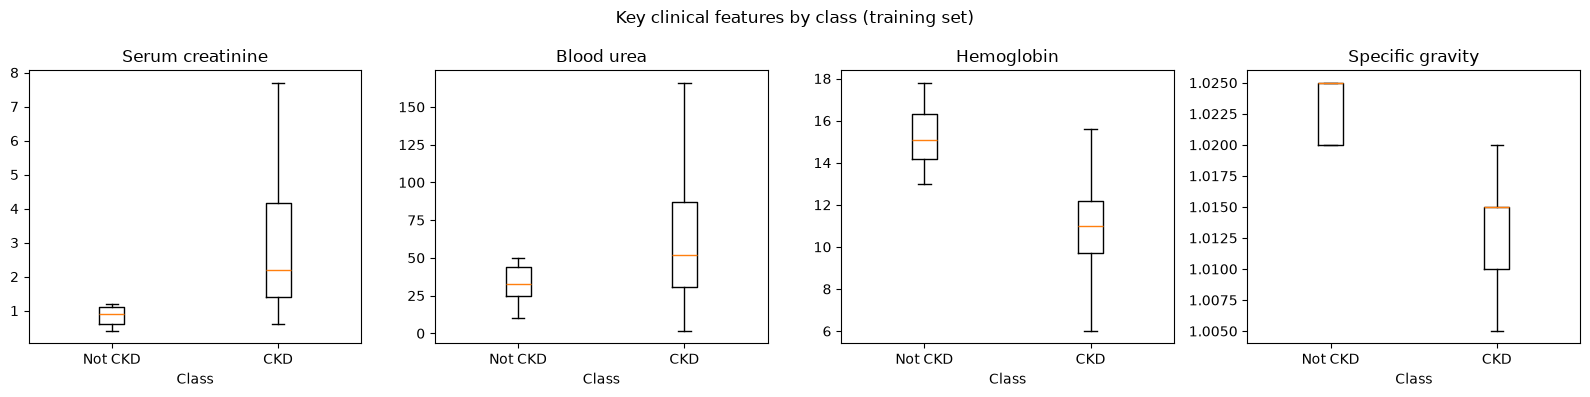

In [3]:
key = ["sc", "bu", "hemo", "sg"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    ax.boxplot([X_train.loc[y_train == c, col].dropna() for c in order], tick_labels=short, showfliers=False)
    ax.set_title(names[col])
    ax.set_xlabel("Class")
fig.suptitle("Key clinical features by class (training set)")
fig.tight_layout()
plt.show()

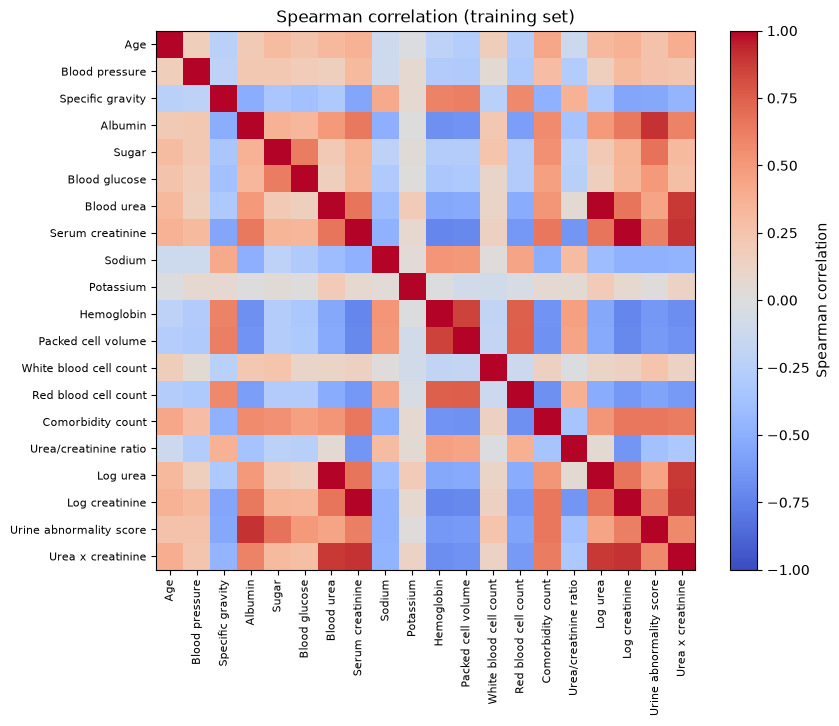

Largest correlation: Blood urea and Log urea, 1.00


In [4]:
corr = X_train[num_cols].corr(method="spearman")
labels = [names[c] for c in num_cols]
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(labels)), labels, rotation=90, fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.title("Spearman correlation (training set)")
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack()
a, b = off.idxmax()
print(f"Largest correlation: {names[a]} and {names[b]}, {off.max():.2f}")

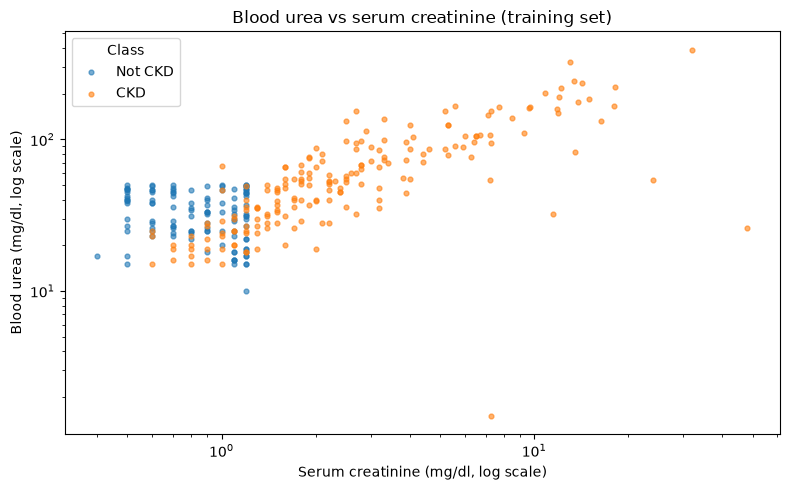

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for c, s in zip(order, short):
    m = y_train == c
    ax.scatter(X_train.loc[m, "sc"], X_train.loc[m, "bu"], s=12, alpha=0.6, label=s)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Serum creatinine (mg/dl, log scale)")
ax.set_ylabel("Blood urea (mg/dl, log scale)")
ax.legend(title="Class")
ax.set_title("Blood urea vs serum creatinine (training set)")
fig.tight_layout()
plt.show()

**Observation:**
- CKD patients have higher creatinine and urea and lower hemoglobin and specific gravity
- Hemoglobin and packed cell volume are strongly correlated (0.86), as expected
- Urea rises with creatinine, as in real patients; both only spread out on a log scale

## 3. Missing values, outliers and impossible values

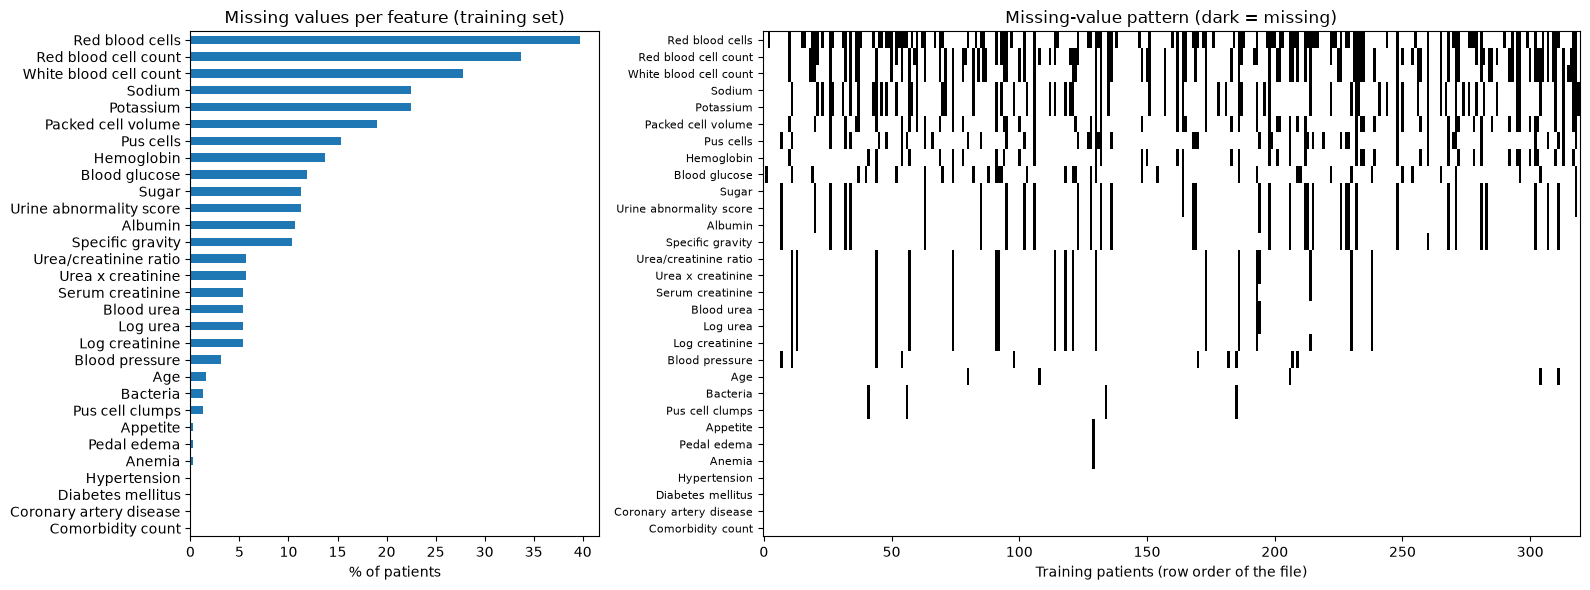

Training rows with at least one missing value: 62%


In [6]:
missing = X_train.isnull().mean().mul(100).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2]})
missing[::-1].rename(index=names).plot(kind="barh", ax=axes[0], title="Missing values per feature (training set)")
axes[0].set_xlabel("% of patients")
axes[1].imshow(X_train[missing.index].isnull().T.values, aspect="auto", cmap="Greys", interpolation="none")
axes[1].set(yticks=range(len(missing)), yticklabels=[names[c] for c in missing.index], xlabel="Training patients (row order of the file)", title="Missing-value pattern (dark = missing)")
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()
print("Training rows with at least one missing value:", f"{X_train.isnull().any(axis=1).mean():.0%}")

In [7]:
q1 = X_train[num_cols].quantile(0.25)
q3 = X_train[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = (X_train[num_cols] < q1 - 1.5 * iqr) | (X_train[num_cols] > q3 + 1.5 * iqr)
display(outliers.sum().sort_values(ascending=False).head(6).rename(index=names).to_frame("Outliers (IQR)"))

,Outliers (IQR)
Sugar,52
Urea x creatinine,48
Serum creatinine,39
Blood glucose,35
Blood urea,30
Blood pressure,29


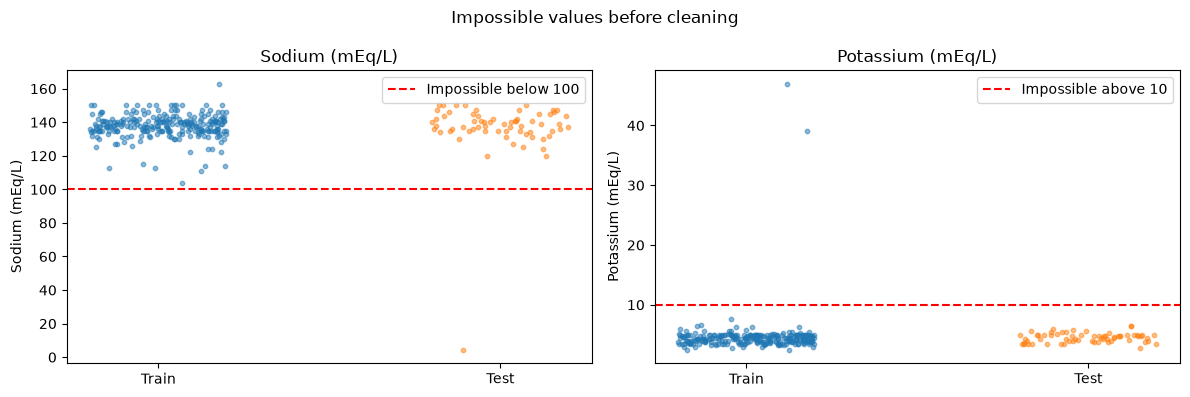

Train: sodium [], potassium [47.0, 39.0]
Test: sodium [4.5], potassium []


In [8]:
limits = {"sod": ("Sodium (mEq/L)", 100, "below"), "pot": ("Potassium (mEq/L)", 10, "above")}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (col, (label, limit, side)) in zip(axes, limits.items()):
    for i, (name, part) in enumerate((("Train", X_train), ("Test", X_test))):
        vals = part[col].dropna()
        ax.scatter(np.random.default_rng(0).uniform(i - 0.2, i + 0.2, len(vals)), vals, s=10, alpha=0.5)
    ax.axhline(limit, color="red", linestyle="--", label=f"Impossible {side} {limit}")
    ax.set(xticks=[0, 1], xticklabels=["Train", "Test"], ylabel=label, title=label)
    ax.legend()
fig.suptitle("Impossible values before cleaning")
fig.tight_layout()
plt.show()

for name, part in (("Train", X_train), ("Test", X_test)):
    low_sod, high_pot = part["sod"] < 100, part["pot"] > 10
    print(f"{name}: sodium {part.loc[low_sod, 'sod'].tolist()}, potassium {part.loc[high_pot, 'pot'].tolist()}")
    part.loc[low_sod, "sod"] = np.nan
    part.loc[high_pot, "pot"] = np.nan

**Observation:**
- Up to 40% missing per feature (red blood cells); dropping rows would lose 62% of training patients, so values are imputed in section 5
- Missing values come in blocks: the same patients often lack red cell count, white cell count, sodium and potassium together
- IQR outliers in sugar, creatinine, glucose and urea are kept, because very high values are expected in kidney failure (KDIGO, 2024)
- 3 impossible values (potassium 47 and 39 in train, sodium 4.5 in test), likely typing errors, set to missing

## 4. Skewed features and the log transform

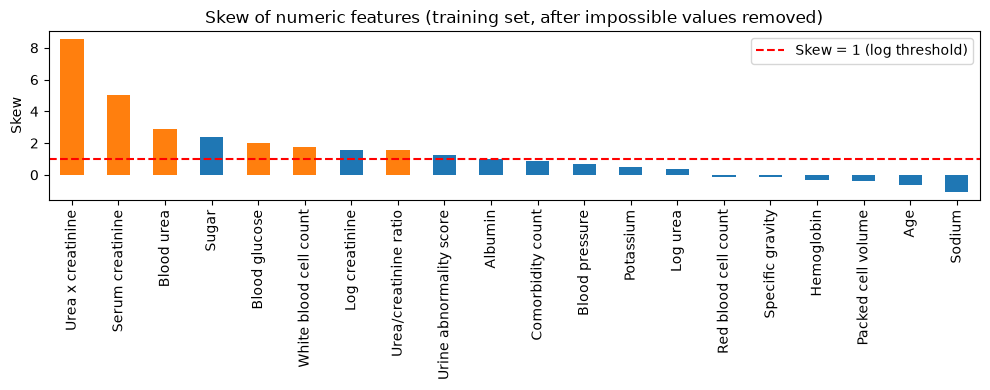

Log-transformed: ['Blood glucose', 'Blood urea', 'Serum creatinine', 'White blood cell count', 'Urea/creatinine ratio', 'Urea x creatinine']


In [9]:
graded = ["sg", "al", "su", "comorbidity_count", "urine_abnormality_score", "log_bu", "log_sc"]  # scales, scores, or already logged
skew = X_train[num_cols].skew().sort_values(ascending=False)
skewed = [c for c in num_cols if c not in graded and skew[c] > 1]

ax = skew.rename(index=names).plot(kind="bar", figsize=(10, 4), color=["C1" if c in skewed else "C0" for c in skew.index])
ax.axhline(1, color="red", linestyle="--", label="Skew = 1 (log threshold)")
ax.set(ylabel="Skew", title="Skew of numeric features (training set, after impossible values removed)")
ax.legend()
plt.tight_layout()
plt.show()
print("Log-transformed:", [names[c] for c in skewed])

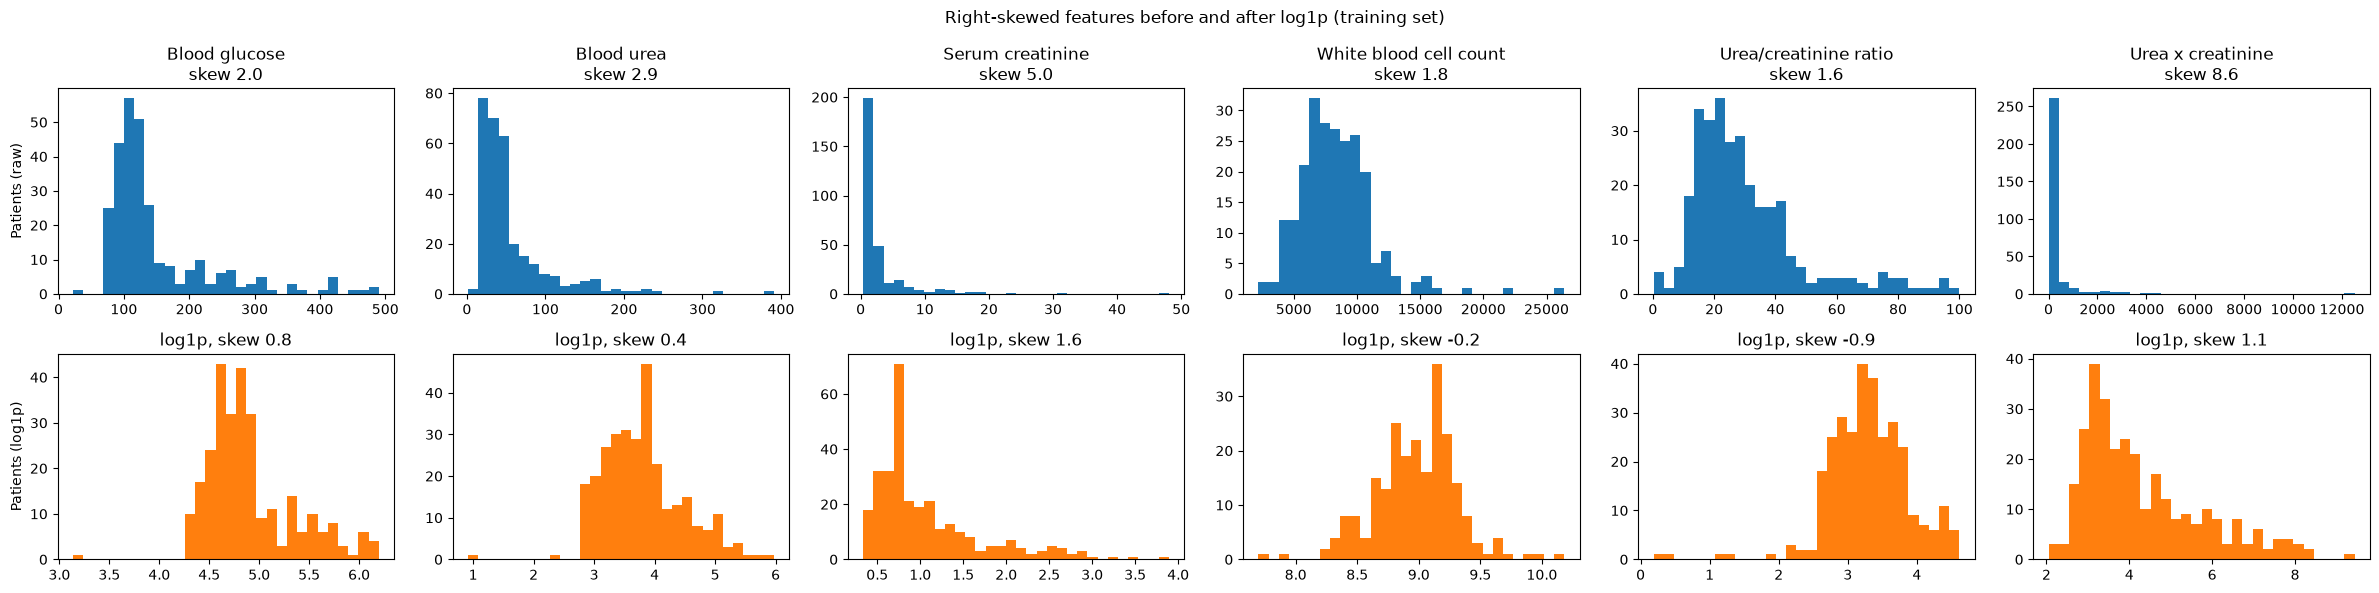

In [10]:
fig, axes = plt.subplots(2, len(skewed), figsize=(4 * len(skewed), 6))
for j, col in enumerate(skewed):
    raw, logged = X_train[col].dropna(), np.log1p(X_train[col].dropna())
    axes[0, j].hist(raw, bins=30)
    axes[0, j].set_title(f"{names[col]}\nskew {raw.skew():.1f}")
    axes[1, j].hist(logged, bins=30, color="C1")
    axes[1, j].set_title(f"log1p, skew {logged.skew():.1f}")
axes[0, 0].set_ylabel("Patients (raw)")
axes[1, 0].set_ylabel("Patients (log1p)")
fig.suptitle("Right-skewed features before and after log1p (training set)")
fig.tight_layout()
plt.show()

**Observation:**
- Glucose, urea, creatinine, white cell count and the engineered urea/creatinine ratio and urea x creatinine have skew above 1, so they are log-transformed; log1p brings the skew down (creatinine 5.0 to 1.6, urea 2.9 to 0.4, glucose 2.0 to 0.8, white cells 1.8 to -0.2, urea/creatinine ratio 1.6 to -0.9, urea x creatinine 8.6 to 1.1)
- Potassium is no longer skewed once the two impossible values are removed, so it is not log-transformed
- Specific gravity, albumin and sugar are graded scales with a few levels, kept without a log transform; the engineered comorbidity count and urine abnormality score are scores, and log urea and log creatinine are already logged, so they are not logged again

## 5. Impute, encode and scale

In [11]:
binary_cats = {
    "rbc": ["normal", "abnormal"],
    "pc": ["normal", "abnormal"],
    "pcc": ["notpresent", "present"],
    "ba": ["notpresent", "present"],
    "htn": ["no", "yes"],
    "dm": ["no", "yes"],
    "cad": ["no", "yes"],
    "appet": ["good", "poor"],
    "pe": ["no", "yes"],
    "ane": ["no", "yes"],
}
unknown = set(text_cols) - set(binary_cats)
assert not unknown, f"New text columns need an encoding: {unknown}"

other_num = [c for c in num_cols if c not in skewed]

preprocess = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), other_num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OrdinalEncoder(categories=[binary_cats[c] for c in text_cols])), text_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape, "missing after:", X_train_prep.isnull().sum().sum() + X_test_prep.isnull().sum().sum())
display(X_train_prep.head())

(320, 30) (80, 30) missing after: 0


,bgr,bu,sc,wbcc,urea_creatinine_ratio,bu_sc_interaction,age,bp,sg,al,...,rbc,pc,pcc,ba,htn,dm,cad,appet,pe,ane
380,-0.366492,-0.950125,-0.505884,-0.687628,-0.380625,-0.729950,0.469875,-1.313179,0.412298,-0.684861,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
56,-0.223696,2.031924,2.092884,1.240055,-0.737201,2.205567,1.486223,-0.514287,-0.503920,1.622039,...,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
126,0.209884,1.614811,0.878642,0.122234,0.302862,1.378500,1.127512,1.083498,-0.503920,-0.684861,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0
371,-1.215166,0.215804,-1.042892,-0.687628,2.321065,-0.738158,-1.383468,-1.313179,1.328515,-0.684861,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
333,-0.680465,0.089465,-0.431639,-2.127836,0.653880,-0.186677,-1.682394,0.284605,0.412298,-0.684861,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
learned = []
for step, cols in (("log", skewed), ("num", other_num), ("cat", text_cols)):
    pipe = preprocess.named_transformers_[step]
    fill = pipe.steps[0][1].statistics_
    scale = pipe.steps[-1][1] if step != "cat" else None
    for i, c in enumerate(cols):
        learned.append({"Feature": names[c], "Step": step, "Fill value": fill[i],
                        "Mean": scale.mean_[i] if scale else np.nan, "Std": scale.scale_[i] if scale else np.nan})
display(pd.DataFrame(learned).set_index("Feature").round(3))

,Step,Fill value,Mean,Std
Feature,,,,
Blood glucose,log,120.0,4.889,0.417
Blood urea,log,41.0,3.792,0.646
Serum creatinine,log,1.2,1.059,0.627
White blood cell count,log,8000.0,8.977,0.287
Urea/creatinine ratio,log,25.833333,3.302,0.566
Urea x creatinine,log,46.4,4.290,1.398
Age,num,54.0,51.141,16.727
Blood pressure,num,80.0,76.438,12.517
Specific gravity,num,1.02,1.018,0.005


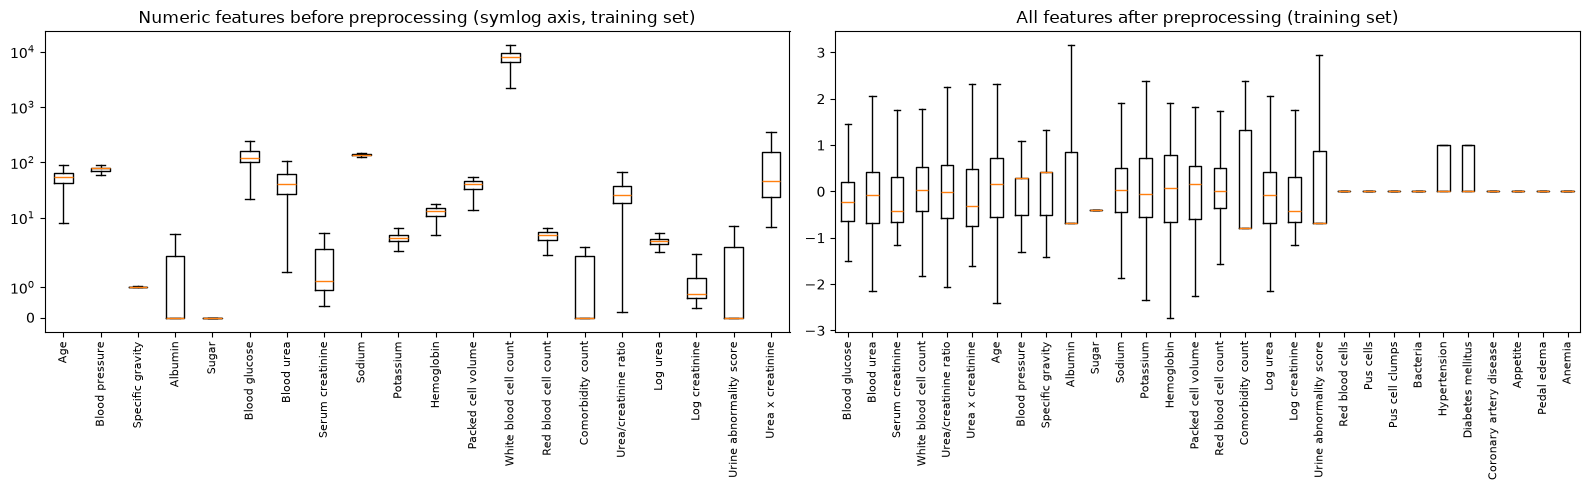

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].boxplot([X_train[c].dropna() for c in num_cols], tick_labels=[names[c] for c in num_cols], showfliers=False)
axes[0].set_yscale("symlog")
axes[0].set_title("Numeric features before preprocessing (symlog axis, training set)")
axes[1].boxplot([X_train_prep[c] for c in X_train_prep.columns], tick_labels=[names[c] for c in X_train_prep.columns], showfliers=False)
axes[1].set_title("All features after preprocessing (training set)")
for ax in axes:
    ax.tick_params(axis="x", rotation=90, labelsize=8)
fig.tight_layout()
plt.show()

**Observation:**
- Missing values filled with the training median (numeric) or most frequent value (text), learned on train only (Géron, 2022)
- Skewed features are log-transformed first, then all numeric features are scaled (mean 0, std 1) so that no feature dominates the distances used by kNN, the MLP and clustering
- The fill values, means and stds in the table come from the 320 training patients and are reused unchanged on the test set
- Binary text features encoded 0/1 (abnormal, present, poor or yes = 1)
- No missing values remain; after preprocessing all numeric features share the same scale
- Limitation: the fill values and scaling are learned on all 320 training rows, so in cross-validation each fold sees statistics that include its validation rows; the effect is small here (medians of 320 vs 256 rows), and the test set is never used

## 6. Save the preprocessed data

In [14]:
out = ds["files"]["preprocessed"]
(base / out["train"]).parent.mkdir(exist_ok=True)

X_train_prep.assign(**{target: y_train.values}).to_csv(base / out["train"], index=False)
X_test_prep.assign(**{target: y_test.values}).to_csv(base / out["test"], index=False)
print(len(X_train_prep), "train rows,", len(X_test_prep), "test rows,", X_train_prep.shape[1], "features")

320 train rows, 80 test rows, 30 features


**Observation:**
- Same short column names as the config; Target kept as text (ckd, notckd)
- Clustering, kNN, Naive Bayes and the MLP use these files, as they need scaled data with no missing values

**GenAI:** code generated with Claude (Anthropic) under the course GenAI policy (Framework statement 6), then evaluated by me.